# Processing of UAWOS ECT Echologger payload data
## Authors: Peter Bauer-Gottwein (pbg@ign.ku.dk)

# Preliminaries
This jupyter notebook documents the data processing workflow for the UAWOS ECT Echologger payload. We demonstrate the data processing workflow for one example from the Torne River. We only include basic Level-2 and Level-3 processing steps. All necessary Level-1 data, auxiliary data and code files to run this notebook are included in a folder "ECT_processing_example", which is distributed with this notebook and is expected to sit in the directory from which this notebook is run. The ECT_processing_example folder also contains a listing of the UAWOS python environment and a corresponding .yaml file. Please install this environment (e.g. using conda) prior to running the notebook. 

# Level 1 data
A echologger (or sonar) survey consists of at least one cross section flight across the river. Typically there is one individual set of files for each cross section. Each flight may contain multiple crossings of the river, which have to be separated and overlaid in data processing. The standard case is that the drone crosses the river twice, i.e. forth and back.

The following files (with acquisition UTC time stamps in the file name) will be available for each ECT cross section flight:

* A *-position.csv file (e.g. 2024-09-07-08-07-46-position.csv in our example), which contains the drone positioning information from SkyHub and the depths recorded by the echologger.
* A *-nmea.txt file (e.g. 2024-09-07-08-07-46-nmea.txt in our example), which contains the primary NMEA sentences coming from the Echologger sensor. Normally this file is not used in processing, but it is useful for QA and to follow up on any issues that may occur
* The Echologger can be set to record full waveform data, which are then stored in a SEGY (.sgy) file that carries the same UTC time stamp as the other files. This file is not available by default.

# Auxiliary data
The following auxiliary data files and items are required to process an LX80 dataset:
* A cross section shapefile (chain_XSline_Torne_utm.shp in our case). This shapefile should be in the target projection of the survey (EPSG:3006) in our case. It should be a point shapefile with points every 0.1 m along the cross section line. Depending on the size of the river etc., other point spacings may be used. You can produce this file from any river cross section line shapefile, for instance using the QGIS plugin "QChainage". The usual convention is that the cross section coordinate should increase from the left bank to the right bank of the river (left and right are defined looking downstream), and that coordinate 0 should be at the intersection with the river centerline. If ground truth data is available, the cross section line may be placed along the ground truth points, to facilitate direct comparison between ECT and ground truth data.
* A geotiff file giving the elevation of the target geoid above the WGS84 ellipsoid at suitable spatial resolution (e.g. 10m) In our example, we use SWEN17_RH2000 (EPSG:5613) as the geoid and the file is Torne_SWEN17_RH2000_3006.tif.
* The EPSG code for the target projection (EPSG:3006 in our case)
* The EPSG code for the target geoid (EPSG:5613 in our case)
* The identifier of the chainage field in the attribute table of the cross section shapefile. If you use QChainage, the identifier will be "cngmeters"
* The WSE of the river (relative to the chosen geoid or WGS84) at the cross section. This is required to convert depth measured by the WPR into riverbed elevation.

# Processing
## 1. Preparing the cross section shapefile
This can be done in QGIS. Go through the following steps:
1. Load the *position.csv file into QGIS as a comma-separated text layer.
2. Create a new line shapefile
3. Create a new shape feature for the reference cross section line
4. Chop up the line into equally spaced points (e.g. 0.2 m), using for instance QGIS plugin "QChainage"
5. Adjust the "cngmeters" field to ensure coordinate zero is at the river centerline.

## 2. Fligth Pre-Processing
First, let's import all required packages:

In [1]:
import os
my_path = r'h:\UAWOS\uawos_data_processing' + os.sep + 'ECT_processing_example'

from UAWOS_ECT_flight import UAWOS_ECT_flight

We provide inputs for auxiliary data and flight data. The flight-specific data block can be copied as many times as there are profile flights in the survey:

In [2]:
Torne_general_attributes = dict()

Torne_general_attributes['Water temperature'] = 15
Torne_general_attributes['Speed of sound in water'] = 1404.3 + 4.7*Torne_general_attributes['Water temperature'] - 0.04*Torne_general_attributes['Water temperature']**2
Torne_general_attributes['xy_EPSG'] = 'EPSG:3006'
Torne_general_attributes['z_EPSG'] = 'EPSG:5613'
Torne_general_attributes['geoid_tiff'] = my_path + os.sep + r'Torne_SWEN17_RH2000_3006.tif'

Torne_1_attributes = Torne_general_attributes.copy()

Torne_1_attributes['name_posfile'] = my_path + os.sep + r'2024-09-07-08-07-46-position.csv'
Torne_1_attributes['name_isfile'] = my_path + os.sep + r''
Torne_1_attributes['refline_file'] = my_path + os.sep + r'chain_XSline_Torne_utm.shp'
Torne_1_attributes['chainage_field'] = 'cngmeters'
Torne_1_attributes['WSE'] = 46.4
Torne_1_attributes['CL_dist_threshold'] = 100
Torne_1_attributes['Manual_pick'] = False
Torne_1_attributes['FWF_data'] = False
Torne_1_attributes['RTK_on'] = True
Torne_1_attributes['Start_sample'] = 1870
Torne_1_attributes['End_sample'] = 9600

Torne_1 = UAWOS_ECT_flight(Torne_1_attributes)

UAWOS Echologger ECT flight class constructor


We now project the data on the reference line and plot the drone elevation and the drone cross section coordinate vs the sample number to understand when the cross section flights start and end:

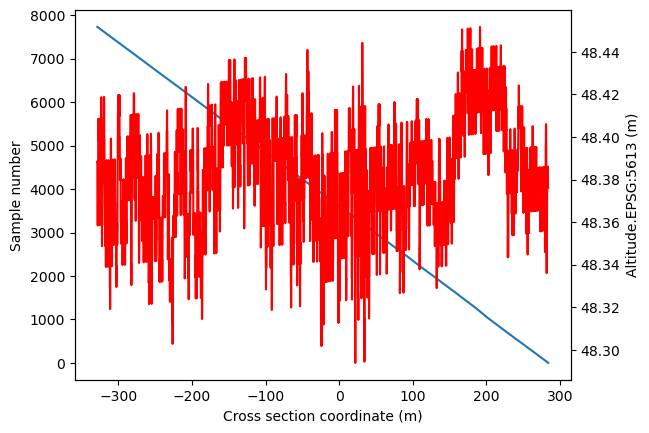

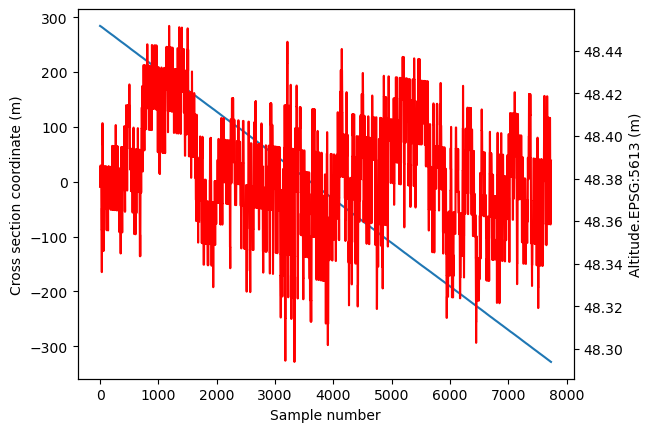

In [3]:
Torne_1 = Torne_1.process_ECT()
Torne_1.plot_Alt_Snum_vs_XS_coord()
Torne_1.plot_XS_coord_Alt_vs_Snum()

From the plots it is clear that the cross section flight starts at around sample number 1870 (low and constant altitude, uniform movement in cross section direction starts) and lasts until sample 9600 or so. We can use these samples to calculate the water surface elevation:

In [4]:
Torne_1.find_WSE()

48.37726967799152
1.9805442757208378
WSE =  46.18672540227068


Now, we can plot the bathymetry cross section:

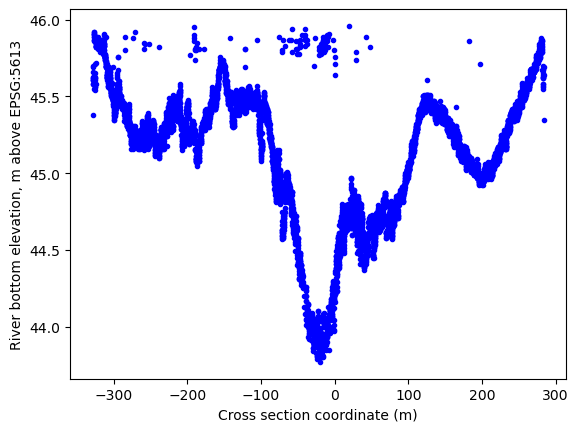

In [5]:
Torne_1.plot_XS()

In [6]:
Torne_1.save_output_data()

And make one final plot with both bottom elevation and WSE:

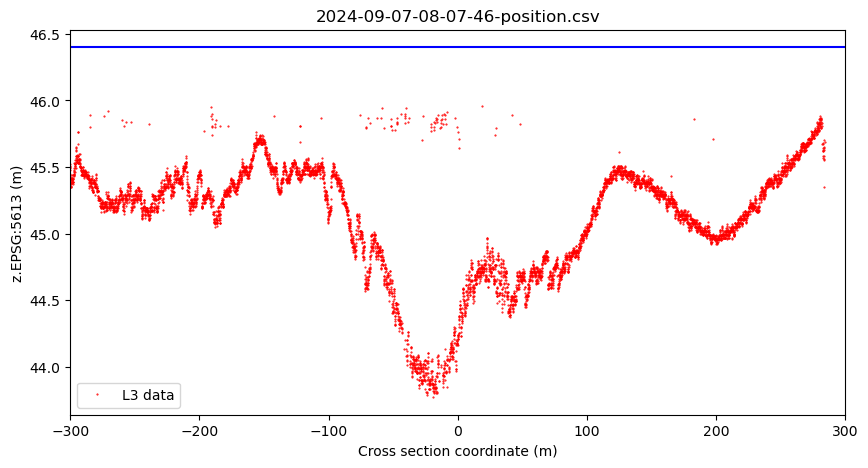

In [7]:
Torne_1.plot_ECT_results([-300,300])